# Minimum-curvature raceline from a SLAM map

Turns a track's occupancy grid into the racing line `pure_pursuit_node` drives. It follows
the planning chain of Olausson & Larsson (2021), *Trajectory planning and control for
autonomous racing*: sections 3.3–3.4 (theory) and 4.2–4.3 (implementation), which build on
the minimum-curvature formulation of Heilmeier et al. (TUM).

- **In:** `rc_maps/tracks/<track>/map.yaml` and its image, in ROS `map_server` format.
- **Out:** `rc_maps/tracks/<track>/racingline.csv`: the line that minimizes $\sum_i k_i^2$,
  with a speed profile.

| Step | Thesis | Content |
|---|---|---|
| 1 | 4.2.1 | Map loading, `map_server` semantics |
| 2 | 4.2.1 | Centerline: Euclidean distance transform + watershed |
| 3 | 4.2.1 | Ordering, Savitzky–Golay, cubic spline, uniform sampling, normals, track widths |
| 4 | 3.3 | The spline system $A$ and the operators $T_c$, $T_{n,x}$, $T_{n,y}$ |
| 5 | 3.3 / 4.2.2 | QP: $\min\ \alpha^T H \alpha + f^T\alpha$ with box constraints |
| 6 | 4.2.2 | Iteration: the previous solution becomes the new centerline |
| 7 | — | Validation against the track boundaries |
| 8 | 3.4 / 4.3 | Speed profile with predictive braking |
| 9 | 6.1 | Figures |
| 10 | 7 | The two tuning parameters, measured |
| 11 | — | Export |

Run it top to bottom. It needs `numpy scipy scikit-image matplotlib pillow pyyaml`.

## 0. Setup

The thesis formulates the QP in CasADi and solves it with Qrqp. Here SciPy solves the same
problem: it is convex with box constraints only, so both reach the same minimizer. The
note in step 5 says why it can be written as a *bounded linear least squares*.

In [1]:
from pathlib import Path
import time
from typing import NamedTuple

from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy import ndimage
from scipy.interpolate import CubicSpline
from scipy.optimize import lsq_linear
from scipy.signal import savgol_filter
from scipy.sparse import csc_matrix, lil_matrix
from scipy.sparse.linalg import splu
from skimage.morphology import skeletonize
from skimage.segmentation import watershed
import yaml

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

In [2]:
TRACK = 'spielberg'                 # a folder under rc_maps/tracks/
TRACK_DIR = Path('../src/rc_maps/tracks') / TRACK
COUNTER_CLOCKWISE = True            # driving direction of the lap

# Planner. D_INTERP is the thesis's one tunable (1.0 m, section 6.1). ALPHA_MARGIN is
# this notebook's addition, step 7 says why. Step 10 measures both.
D_INTERP = 1.00       # [m] spacing of the centerline samples
W_CAR = 0.33          # [m] car width
N_ITER = 2            # QP iterations, as in the thesis
ALPHA_MARGIN = 0.20   # [m] kept free on each side, on top of W_CAR / 2

# Speed profile (sections 3.4 / 4.3)
A_LAT_MAX = 6.00      # [m/s^2] lateral limit: v_crit = sqrt(A_LAT_MAX * R)
A_ACC = 3.00          # [m/s^2] acceleration
A_BRAKE = -5.00       # [m/s^2] braking, negative
V_MAX = 10.25         # [m/s] the thesis's value, section 6.1
HORIZON = 40          # points the braking logic looks ahead
T_MARGIN = 0.50       # [m] threshold T in (4.8)

## 1. Map loading

`map_server` semantics: with `negate: 0` a pixel value $p\in[0,255]$ means occupancy
$occ = 1 - p/255$, and a pixel is free where $occ <$ `free_thresh`.

Two coordinate conventions meet here:

* **image row 0 is the top** and holds the *largest* $y$
* `origin` in the YAML is the world coordinate of the image's **lower-left** corner

The thesis assumes a binary map that the mapping module has already filtered (ch. 1.4).

In [3]:
class GridMap(NamedTuple):
    img: np.ndarray      # grey values as loaded, for plotting
    free: np.ndarray     # True where the car may be
    edt: np.ndarray      # [px] distance to the nearest non-free pixel
    res: float           # [m/px]
    origin: np.ndarray   # world (x, y) of the lower-left corner


def load_map(yaml_path):
    """Load a map_server map. The image path is relative to the YAML, as map_server reads it."""
    yaml_path = Path(yaml_path)
    with open(yaml_path) as fh:
        meta = yaml.safe_load(fh)
    img = np.array(Image.open(yaml_path.parent / meta['image']).convert('L'), dtype=float)
    p = img / 255.0
    occupancy = p if meta.get('negate', 0) else 1.0 - p
    free = occupancy < meta.get('free_thresh', 0.196)
    return GridMap(img, free, ndimage.distance_transform_edt(free),
                   float(meta['resolution']), np.array(meta['origin'][:2], float))


def px_to_world(rc, m):
    """(row, col) -> (x, y) in metres, at the pixel centre."""
    x = m.origin[0] + (rc[..., 1] + 0.5) * m.res
    y = m.origin[1] + (m.free.shape[0] - 1 - rc[..., 0] + 0.5) * m.res
    return np.stack([x, y], axis=-1)


def world_to_px(xy, m):
    """(x, y) in metres -> fractional (row, col)."""
    c = (xy[..., 0] - m.origin[0]) / m.res - 0.5
    r = (m.free.shape[0] - 1) - ((xy[..., 1] - m.origin[1]) / m.res - 0.5)
    return np.stack([r, c], axis=-1)


MAP = load_map(TRACK_DIR / 'map.yaml')
print(f'Track      : {TRACK}')
print(f'Size       : {MAP.free.shape[1]} x {MAP.free.shape[0]} px')
print(f'Resolution : {MAP.res} m/px')
print(f'Origin     : {MAP.origin}')
print(f'Free area  : {MAP.free.sum():,} px ({MAP.free.mean() * 100:.1f} %)')

Track      : spielberg
Size       : 2000 x 2000 px
Resolution : 0.05796 m/px
Origin     : [-84.8536 -36.303 ]
Free area  : 3,960,078 px (99.0 %)


## 2. Centerline by distance transform + watershed

The thesis treats this purely as image processing:

1. Euclidean distance transform of the free area: the middle of the track gets the highest value
2. pick **one pixel group outside the track** and **one inside** as basins
3. watershed floods from both basins; they meet on the ridge, which is the centerline

The ridge has to be **exactly one pixel wide**, or the neighbour search in step 3 fails. So
the result is skeletonized, and the short side branches that SLAM noise leaves are pruned by
removing end points until none are left. A closed loop has no end points, so the track
itself is untouched.

Ridge pixels: 5451 -> 5451 after pruning


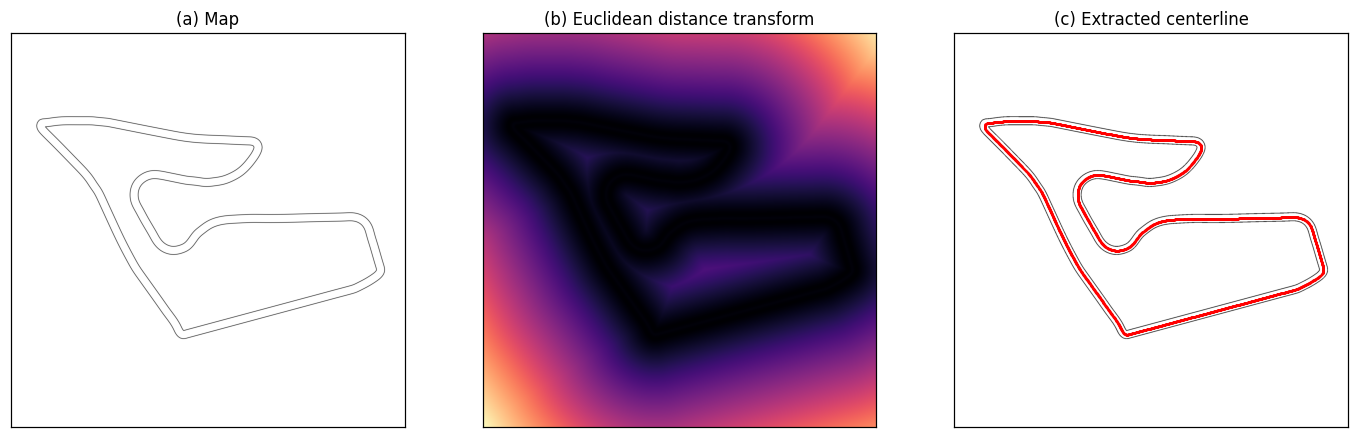

In [4]:
def centerline_mask(m, min_marker_px=20):
    """The ridge of the distance transform, midway between the track's two boundaries."""
    labels, n = ndimage.label(~m.free, structure=np.ones((3, 3)))
    if n < 2:
        raise RuntimeError('found no two blocked regions (outside + infield) - '
                           'is the track closed in the map?')
    sizes = np.bincount(labels.ravel())[1:]
    outside, infield = np.argsort(sizes)[::-1][:2] + 1
    if sizes[infield - 1] < min_marker_px:
        raise RuntimeError('the infield is too small to seed the watershed')

    markers = np.zeros(labels.shape, np.int32)
    markers[labels == outside] = 1
    markers[labels == infield] = 2
    basins = watershed(m.edt, markers, watershed_line=True)
    return skeletonize((basins == 0) & m.free)


def prune_spurs(mask, max_iter=300):
    """Remove end points until none are left: side branches go, the loop stays."""
    mask = mask.copy()
    for _ in range(max_iter):
        neighbours = ndimage.convolve(mask.astype(np.uint8), np.ones((3, 3)), mode='constant')
        ends = mask & (neighbours - mask <= 1)
        if not ends.any():
            break
        mask[ends] = False
    return mask


RIDGE_RAW = centerline_mask(MAP)
RIDGE = prune_spurs(RIDGE_RAW)
print(f'Ridge pixels: {RIDGE_RAW.sum()} -> {RIDGE.sum()} after pruning')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(MAP.img, cmap='gray')
axes[0].set_title('(a) Map')
axes[1].imshow(MAP.edt, cmap='magma')
axes[1].set_title('(b) Euclidean distance transform')
axes[2].imshow(MAP.free, cmap='gray')
rows, cols = np.nonzero(RIDGE)
axes[2].scatter(cols, rows, s=0.12, c='red')
axes[2].set_title('(c) Extracted centerline')
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 3. Ordering, filtering, spline and uniform sampling

The thesis's neighbour search: start at any ridge pixel, step to an unvisited neighbouring
ridge pixel, mark it visited, repeat. 4-neighbours are tried before diagonals, so the walk
does not cut across a bend.

Then a Savitzky–Golay filter (the thesis filters **before** the spline fit), a periodic
cubic spline, and resampling at constant arc length `D_INTERP`. The spline's parameter is
not exactly arc length, so the resampling is repeated a few times.

The normal $n_i$ comes from the tangent and points **left** of the driving direction. The
free width on each side, $W_l$ along $+n_i$ and $W_r$ along $-n_i$, is measured as in the
thesis: walk along the normal to the first non-free pixel.

In [5]:
def order_ridge(mask):
    """Walk the one-pixel ridge into an ordered loop of (row, col) pixels."""
    pixels = np.argwhere(mask)
    if len(pixels) < 8:
        raise RuntimeError('too few centerline pixels')
    unvisited = set(map(tuple, pixels))
    steps = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
    cur, ordered = tuple(pixels[0]), []
    while cur is not None:
        ordered.append(cur)
        unvisited.remove(cur)
        neighbours = ((cur[0] + dr, cur[1] + dc) for dr, dc in steps)
        cur = next((p for p in neighbours if p in unvisited), None)
    if len(ordered) < 0.8 * len(pixels):
        raise RuntimeError(f'the walk covered only {len(ordered)}/{len(pixels)} pixels - '
                           'the ridge is probably not one closed one-pixel loop')
    return np.array(ordered, float)


def signed_area(xy):
    """Shoelace formula: positive for a counter-clockwise loop (x right, y up)."""
    x, y = xy[:, 0], xy[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)


def enforce_direction(xy, counter_clockwise):
    """Reverse the loop if it runs the other way round.

    order_ridge() walks whichever way the pixel scan happens to start. Fixed here,
    tangent, normal, psi and curvature all follow.
    """
    return xy if (signed_area(xy) > 0) == counter_clockwise else xy[::-1]


def closed_spline(pts):
    """Periodic cubic spline through pts over chord length: (spline, knots s)."""
    loop = np.vstack([pts, pts[0]])
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(loop, axis=0), axis=1))])
    return CubicSpline(s, loop, bc_type='periodic'), s


def fit_and_resample(xy, d_interp, savgol_win=21, savgol_poly=3, n_arc=3):
    """Smooth a closed loop of points and resample it every d_interp metres of arc.

    Returns the points, their unit left normals, the distance from each point to
    the next, and the length of the loop.
    """
    pts = np.asarray(xy, float)
    if np.linalg.norm(pts[0] - pts[-1]) < 1e-9:
        pts = pts[:-1]

    window = min(savgol_win, len(pts) - 1)
    if window % 2 == 0:
        window -= 1
    if window > savgol_poly:
        # mode='wrap': the track is periodic
        pts = np.column_stack([savgol_filter(pts[:, i], window, savgol_poly, mode='wrap')
                               for i in (0, 1)])

    spline, s = closed_spline(pts)
    for _ in range(n_arc):
        u = np.linspace(0, s[-1], 4000)
        speed = np.linalg.norm(spline(u, 1), axis=1)
        arc = np.concatenate([[0], np.cumsum(0.5 * (speed[1:] + speed[:-1]) * np.diff(u))])
        n = max(20, int(round(arc[-1] / d_interp)))
        u_even = np.interp(np.linspace(0, arc[-1], n, endpoint=False), arc, u)
        spline, s = closed_spline(spline(u_even))

    pts = spline(s[:-1])
    tangents = spline(s[:-1], 1)
    tangents /= np.linalg.norm(tangents, axis=1, keepdims=True)
    normals = np.column_stack([-tangents[:, 1], tangents[:, 0]])
    ds = np.linalg.norm(np.roll(pts, -1, 0) - pts, axis=1)
    return pts, normals, ds, s[-1]


def track_widths(pts, normals, m, max_dist=25.0, step_frac=0.25):
    """Free distance from each point along +n (left) and -n (right), by marching rays."""
    step = m.res * step_frac
    reach = step * np.arange(1, int(max_dist / step) + 1)
    widths = []
    for side in (1.0, -1.0):
        rays = pts[:, None, :] + (side * normals)[:, None, :] * reach[None, :, None]
        rc = np.rint(world_to_px(rays, m)).astype(int)
        off_map = ((rc < 0) | (rc >= m.free.shape)).any(axis=-1)
        blocked = off_map.copy()
        blocked[~off_map] = ~m.free[tuple(rc[~off_map].T)]
        first = np.where(blocked.any(axis=1), blocked.argmax(axis=1), len(reach))
        widths.append(first * step)
    return widths


def plot_loop(ax, pts, *args, **kwargs):
    ax.plot(*np.vstack([pts, pts[0]]).T, *args, **kwargs)


CENTER_PX = order_ridge(RIDGE)
CENTER_XY = enforce_direction(px_to_world(CENTER_PX, MAP), COUNTER_CLOCKWISE)
P0, N0, DS0, L0 = fit_and_resample(CENTER_XY, D_INTERP)
W_LEFT, W_RIGHT = track_widths(P0, N0, MAP)
LEFT_EDGE = P0 + N0 * W_LEFT[:, None]
RIGHT_EDGE = P0 - N0 * W_RIGHT[:, None]

print(f'Centerline     : {len(CENTER_PX)} pixels -> {len(P0)} samples')
print(f'Direction      : {"counter-clockwise" if COUNTER_CLOCKWISE else "clockwise"}')
print(f'Track length   : {L0:.2f} m')
print(f'Sample spacing : {DS0.min():.3f} - {DS0.max():.3f} m (target {D_INTERP})')
print(f'Track width    : W_l {W_LEFT.min():.2f}-{W_LEFT.max():.2f} m, '
      f'W_r {W_RIGHT.min():.2f}-{W_RIGHT.max():.2f} m')

Centerline     : 5451 pixels -> 343 samples
Direction      : counter-clockwise
Track length   : 342.81 m
Sample spacing : 0.968 - 1.000 m (target 1.0)
Track width    : W_l 1.06-1.22 m, W_r 1.04-1.22 m


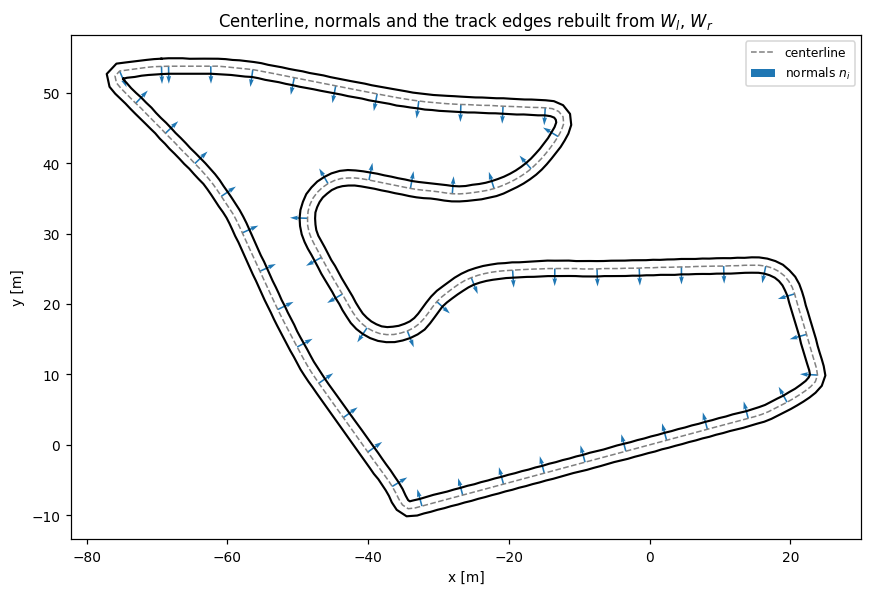

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_loop(ax, LEFT_EDGE, 'k-', lw=1.4)
plot_loop(ax, RIGHT_EDGE, 'k-', lw=1.4)
plot_loop(ax, P0, '--', color='0.5', lw=1, label='centerline')
every = slice(None, None, 6)
ax.quiver(P0[every, 0], P0[every, 1], N0[every, 0], N0[every, 1], color='tab:blue',
          scale=45, width=0.002, label='normals $n_i$')
ax.set_aspect('equal')
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Centerline, normals and the track edges rebuilt from $W_l$, $W_r$')
plt.tight_layout()
plt.show()

## 4. The spline system

The raceline is $r_i = p_i + n_i\alpha_i$: one scalar per point instead of $(x, y)$, which
halves the unknowns and turns the track width into a box constraint. Every segment is a
cubic in the normalized parameter $t\in[0,1]$, $x$ and $y$ handled alike:

$$x_i(t)=a_i+b_it+c_it^2+d_it^3$$

Four conditions per pair of points give the pattern $A_{template}$ (thesis section 3.3):

| Row | Condition | Meaning |
|---|---|---|
| 1 | $x_i(0)=x_i$ | the segment starts at point $i$ |
| 2 | $x_i(1)=x_{i+1}$ | the segment ends at point $i+1$ |
| 3 | $x_i'(1)-x_{i+1}'(0)=0$ | same heading across the joint |
| 4 | $x_i''(1)-x_{i+1}''(0)=0$ | same curvature across the joint |

$A$ is $4N\times 4N$ and block-cyclic: the last block row couples back to segment 0 and
closes the lap.

At $t=0$, $x_i''=2c_i$. The right-hand side is $b = q + M\alpha$, the centerline's
coordinates plus the normal components, so with the extraction matrix $A_{ex,c}$ that picks
every $c_i$:

$$T_c = 2A_{ex,c}A^{-1},\qquad T_{n,x}=T_cM_x,\qquad T_{n,y}=T_cM_y$$
$$\bar x''=T_c\bar q_x+T_{n,x}\alpha,\qquad \bar y''=T_c\bar q_y+T_{n,y}\alpha$$

$A$ is never inverted: one sparse LU factorization serves all $N+1$ right-hand sides, and
that is what keeps this step cheap.

A: (1372, 1372), 4116 non-zeros (0.22 % dense)


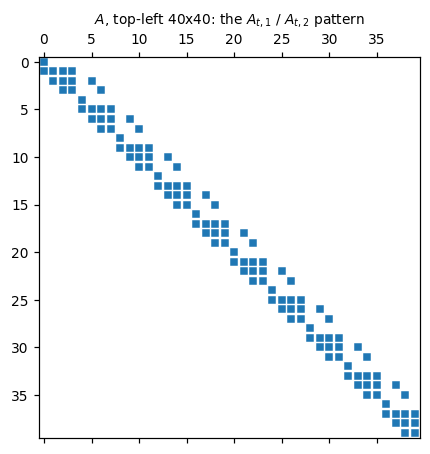

In [7]:
A_T1 = np.array([[1., 0, 0, 0],
                 [1., 1, 1, 1],
                 [0., 1, 2, 3],
                 [0., 0, 2, 6]])
A_T2 = np.array([[0., 0, 0, 0],
                 [0., 0, 0, 0],
                 [0., -1, 0, 0],
                 [0., 0, -2, 0]])


def spline_system(n):
    """A (4n x 4n) for a closed loop of n points, and its sparse LU."""
    a = lil_matrix((4 * n, 4 * n))
    for i in range(n):
        j = (i + 1) % n   # the last block wraps to segment 0
        a[4 * i:4 * i + 4, 4 * i:4 * i + 4] = A_T1
        a[4 * i:4 * i + 4, 4 * j:4 * j + 4] = A_T2
    a = csc_matrix(a)
    return a, splu(a)


def rhs(values):
    """b of A z = b: rows 1 and 2 of block i hold the values at points i and i+1."""
    b = np.zeros((4 * len(values),) + values.shape[1:])
    b[0::4] = values
    b[1::4] = np.roll(values, -1, axis=0)
    return b


def second_derivatives(pts, normals, lu):
    """x'' and y'' at the points, affine in alpha: (T_c q_x, T_c q_y, T_n,x, T_n,y)."""
    def t_c(values):
        return 2.0 * lu.solve(rhs(values))[2::4]   # [2::4] is A_ex,c: every c_i

    return (t_c(pts[:, 0]), t_c(pts[:, 1]),
            t_c(np.diag(normals[:, 0])), t_c(np.diag(normals[:, 1])))


A, _ = spline_system(len(P0))
print(f'A: {A.shape}, {A.nnz} non-zeros ({100 * A.nnz / np.prod(A.shape):.2f} % dense)')

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.spy(A[:40, :40], markersize=4)
ax.set_title('$A$, top-left 40x40: the $A_{t,1}$ / $A_{t,2}$ pattern', fontsize=9)
plt.tight_layout()
plt.show()

## 5. The QP

Squared curvature (eq. 3.15):

$$k_i^2=\frac{x_i''^2y_i'^2-2x_i'x_i''y_i'y_i''+y_i''^2x_i'^2}{(x_i'^2+y_i'^2)^3}$$

**The key assumption:** the raceline's first derivative is taken to be about the
centerline's at the same point. That makes the coefficients constant, $\bar x''$ and
$\bar y''$ are *linear* in $\alpha$, and the whole problem is a QP:

$$\min_\alpha\ \alpha^TH\alpha+f^T\alpha\quad\text{s.t.}\quad
\alpha_i\in\left[-W_r+\tfrac{W_{car}}{2},\ W_l-\tfrac{W_{car}}{2}\right]$$

`ALPHA_MARGIN` tightens both bounds further. The thesis's normal points right, so there
$W_l$ and $W_r$ swap places.

Two notes on the implementation:

1. **Naming.** The thesis writes $P_{xx},P_{xy},P_{yy}$ but switches convention between
   (3.16) and (3.17). Here they are defined from (3.15) as the coefficients of $x''^2$,
   $x''y''$ and $y''^2$. Read that way (4.4)–(4.5) hold exactly; the cell below checks it.

2. **Numerics.** The numerator of (3.15) is a perfect square:
   $k=(x'y''-y'x'')/(x'^2+y'^2)^{3/2}$. So $\sum k_i^2=\lVert G\alpha+g_0\rVert^2$, a
   *bounded linear least squares*. Solving that form is numerically more stable than
   forming $H$, which squares the condition number. $H$ and $f$ are still computed below,
   once, to tie the code to the thesis's equations.

In [8]:
def curvature_model(pts, normals, ds):
    """k = G alpha + g0 for the line pts + alpha * normals, and the terms G and g0 are made of."""
    _, lu = spline_system(len(pts))
    tc_qx, tc_qy, tnx, tny = second_derivatives(pts, normals, lu)

    # First derivatives in the normalized segment parameter t: x' ~ ds * tangent
    tangents = np.roll(pts, -1, 0) - np.roll(pts, 1, 0)
    tangents /= np.linalg.norm(tangents, axis=1, keepdims=True)
    dx, dy = tangents[:, 0] * ds, tangents[:, 1] * ds
    root = (dx**2 + dy**2)**1.5

    G = (dx[:, None] * tny - dy[:, None] * tnx) / root[:, None]
    g0 = (dx * tc_qy - dy * tc_qx) / root
    return G, g0, (dx, dy, root, tc_qx, tc_qy, tnx, tny)


def alpha_bounds(w_left, w_right, w_car, margin):
    """Box constraints on alpha: half the car plus the margin stays free on both sides."""
    lb = -w_right + w_car / 2.0 + margin
    ub = w_left - w_car / 2.0 - margin
    narrow = lb >= ub
    if narrow.any():
        # lsq_linear needs lb < ub strictly. Where the car does not fit, alpha is
        # pinned to the middle of the track by a box of 2 micrometres.
        mid = 0.5 * (lb + ub)
        lb = np.where(narrow, mid - 1e-6, lb)
        ub = np.where(narrow, mid + 1e-6, ub)
        print(f'  warning: the car and its margin do not fit at {narrow.sum()} point(s)')
    return lb, ub


def solve_alpha(G, g0, lb, ub):
    """min ||G alpha + g0||^2 = sum k^2 within the bounds."""
    sol = lsq_linear(G, -g0, bounds=(lb, ub), method='trf', tol=1e-10, max_iter=200)
    if sol.status == 0:
        print('  warning: lsq_linear stopped at max_iter before converging')
    return sol.x


G, g0, (dx, dy, root, tc_qx, tc_qy, tnx, tny) = curvature_model(P0, N0, DS0)
LB, UB = alpha_bounds(W_LEFT, W_RIGHT, W_CAR, ALPHA_MARGIN)
ALPHA1 = solve_alpha(G, g0, LB, UB)

# H and f as the thesis writes them, (4.4)-(4.5)
p_x2 = dy**2 / root**2           # coefficient of x''^2
p_xy = -2 * dx * dy / root**2    # coefficient of x'' y''
p_y2 = dx**2 / root**2           # coefficient of y''^2
cross = (tnx.T * p_xy) @ tny
H = (tnx.T * p_x2) @ tnx + (tny.T * p_y2) @ tny + 0.5 * (cross + cross.T)
f = (2 * (tnx.T * p_x2) @ tc_qx + 2 * (tny.T * p_y2) @ tc_qy
     + (tnx.T * p_xy) @ tc_qy + (tny.T * p_xy) @ tc_qx)

at_bound = (ALPHA1 <= LB + 1e-6) | (ALPHA1 >= UB - 1e-6)
print(f'alpha       : [{ALPHA1.min():+.3f}, {ALPHA1.max():+.3f}] m')
print(f'at a bound  : {at_bound.sum()}/{len(ALPHA1)} points')
print(f'H           : symmetric={np.allclose(H, H.T)}, '
      f'smallest eigenvalue {np.linalg.eigvalsh(H).min():.3e}')
print(f'sum k^2     : {np.sum((G @ ALPHA1 + g0)**2):.6f} as least squares, '
      f'{ALPHA1 @ H @ ALPHA1 + f @ ALPHA1 + g0 @ g0:.6f} from H and f')

alpha       : [-0.751, +0.838] m
at a bound  : 31/343 points
H           : symmetric=True, smallest eigenvalue 4.632e-06
sum k^2     : 0.902535 as least squares, 0.902535 from H and f


## 6. The iteration

Freezing the first derivatives makes the solution approximate. So the thesis runs the
optimization twice, with the previous raceline as the centerline of the next pass. After
each pass the normals and the widths are measured again from the new baseline.

On this track one pass is not enough: $\sum k_i^2$ is *higher* after the first pass than on
the centerline, and only the second brings it down.

In [9]:
def path_curvature(pts):
    """Signed curvature of the closed spline through pts, each point's s, and the length."""
    spline, s = closed_spline(pts)
    d1, d2 = spline(s[:-1], 1), spline(s[:-1], 2)
    k = (d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]) / np.maximum(
        np.linalg.norm(d1, axis=1)**3, 1e-12)
    return k, s[:-1], s[-1]


def sum_k2(pts):
    return float(np.sum(path_curvature(pts)[0]**2))


def minimum_curvature(pts, normals, ds, w_left, w_right, m, w_car=W_CAR, n_iter=N_ITER,
                      d_interp=D_INTERP, margin=ALPHA_MARGIN, verbose=True):
    """Iterate the QP. Returns the raceline and, per pass, its sum k^2 and length."""
    history = [dict(sum_k2=sum_k2(pts), length=float(np.sum(ds)))]
    for it in range(1, n_iter + 1):
        G, g0, _ = curvature_model(pts, normals, ds)
        alpha = solve_alpha(G, g0, *alpha_bounds(w_left, w_right, w_car, margin))
        pts, normals, ds, length = fit_and_resample(pts + normals * alpha[:, None], d_interp,
                                                    savgol_win=5)
        w_left, w_right = track_widths(pts, normals, m)
        history.append(dict(sum_k2=sum_k2(pts), length=float(length)))
        if verbose:
            print(f'  pass {it} : N={len(pts):4d}  sum k^2={history[-1]["sum_k2"]:.4f}  '
                  f'length={length:.2f} m')
    return pts, history


print(f'Minimum-curvature optimization, {N_ITER} passes:')
print(f'  start  : N={len(P0):4d}  sum k^2={sum_k2(P0):.4f}  length={L0:.2f} m')
RACE, HISTORY = minimum_curvature(P0, N0, DS0, W_LEFT, W_RIGHT, MAP)

K_CENTER, K_RACE = path_curvature(P0)[0], path_curvature(RACE)[0]
print(f'\nTotal squared curvature : {np.sum(K_CENTER**2):.4f} -> {np.sum(K_RACE**2):.4f} '
      f'({100 * (1 - np.sum(K_RACE**2) / np.sum(K_CENTER**2)):.1f} % less)')
print(f'Largest curvature       : {np.abs(K_CENTER).max():.4f} -> {np.abs(K_RACE).max():.4f} 1/m')
print(f'Tightest radius         : {1 / np.abs(K_CENTER).max():.2f} -> '
      f'{1 / np.abs(K_RACE).max():.2f} m')

Minimum-curvature optimization, 2 passes:
  start  : N= 343  sum k^2=7.4224  length=342.81 m


  pass 1 : N= 337  sum k^2=9.9578  length=336.45 m


  pass 2 : N= 338  sum k^2=2.1262  length=338.32 m

Total squared curvature : 7.4224 -> 2.1262 (71.4 % less)
Largest curvature       : 1.2303 -> 0.4272 1/m
Tightest radius         : 0.81 -> 2.34 m


## 7. Validation against the track boundaries

The thesis's most important known weakness (chapter 7): **the QP bounds $\alpha$ at the
sample points only, not the spline between them.** With too coarse an interpolation
distance the raceline can leave the track while every $\alpha_i$ is inside its bounds.

The check below samples the finished line densely and reads its clearance from the
distance transform: the **shortest distance in any direction**, exact to about one pixel.

Two independent effects can push the clearance below $W_{car}/2$ although every
$\alpha_i$ respects its bound:

1. **The spline between the sample points.** The constraint holds at the points only.
   This is the effect the thesis names, and `D_INTERP` controls it.
2. **$W_l$ and $W_r$ are measured *along the normal*.** In a bend the distance along the
   normal to the track edge is longer than the perpendicular distance to the nearest
   wall. The constraint is therefore always a little too generous at an apex, however
   finely one interpolates.

`ALPHA_MARGIN` covers both and is the quick remedy; `D_INTERP` addresses only the first.

In [10]:
def validate(pts, m, w_car, n_dense=8000):
    """Clearance along the finished line, sampled far denser than the QP's points."""
    spline, s = closed_spline(pts)
    rc = world_to_px(spline(np.linspace(0, s[-1], n_dense)), m).round().astype(int)
    rows = np.clip(rc[:, 0], 0, m.free.shape[0] - 1)
    cols = np.clip(rc[:, 1], 0, m.free.shape[1] - 1)
    clearance = m.edt[rows, cols] * m.res
    n_outside = int((~m.free[rows, cols]).sum())
    return dict(clearance=clearance, min_clearance=float(clearance.min()), n_outside=n_outside,
                ok=bool(n_outside == 0 and clearance.min() >= w_car / 2.0))


CHECK = validate(RACE, MAP, W_CAR)
print(f'Samples off the track : {CHECK["n_outside"]} / {len(CHECK["clearance"])}')
print(f'Smallest clearance    : {CHECK["min_clearance"]:.3f} m '
      f'(needs W_car/2 = {W_CAR / 2:.3f} m)')
print('Result                :',
      'OK' if CHECK['ok'] else 'NOT DRIVABLE - raise ALPHA_MARGIN or lower D_INTERP')

Samples off the track : 0 / 8000
Smallest clearance    : 0.259 m (needs W_car/2 = 0.165 m)
Result                : OK


## 8. Speed profile

Critical speed per point (eq. 3.26):

$$v_{critical}=\sqrt{\frac{f_n^{max}R}{m}}=\sqrt{a_{lat}^{max}R}$$

The thesis (section 4.3) replaces Velenis & Tsiotras's minimization over characteristics
with a **predictive** variant: for every point $k$, the braking distance to each point
within the horizon,

$$t=\frac{V_x^{crit}-v_k}{a},\qquad s_{brake}=v_kt+\tfrac12at^2$$

and where the margin to that point falls below the threshold $T$, the deceleration it
takes; otherwise full acceleration.

> Equation (4.8) reads $s_{brake}-\lVert k-x\rVert>T$ in the thesis, with braking when the
> condition does *not* hold. Taken literally that brakes when the braking distance is
> *shorter* than the distance, which is backwards. Implemented here is the intended
> meaning: brake when the margin $\lVert k-x\rVert-s_{brake}$ falls below $T$.

The track is closed, so the sweep runs a few laps to carry the braking across the
start/finish line.

The decision is taken point by point, so by the time the margin falls below $T$ the
deceleration it takes can already exceed `A_BRAKE`. The printout shows by how much.

In [11]:
def plan_velocity(pts, a_lat_max=A_LAT_MAX, a_acc=A_ACC, a_brake=A_BRAKE, v_max=V_MAX,
                  horizon=HORIZON, t_margin=T_MARGIN, n_pass=4):
    """Speed at every point: the critical speed, capped, then braking and acceleration."""
    k, s, length = path_curvature(pts)
    radius = 1.0 / np.maximum(np.abs(k), 1e-6)
    v_crit_raw = np.sqrt(a_lat_max * radius)   # (3.26), before the V_MAX cap
    v_crit = np.minimum(v_crit_raw, v_max)
    n = len(pts)
    ds = np.diff(np.concatenate([s, [length]]))

    v = v_crit.copy()
    for lap in range(n_pass):
        for i in range(n):
            a_req = a_acc
            dist = 0.0
            for j in range(1, horizon + 1):
                x = (i + j) % n
                dist += ds[(i + j - 1) % n]
                if v_crit[x] >= v[i]:
                    continue
                t_brake = (v_crit[x] - v[i]) / a_brake                # (4.7)
                s_brake = v[i] * t_brake + 0.5 * a_brake * t_brake**2  # (4.6)
                if dist - s_brake < t_margin:                          # (4.8), as intended
                    a_req = min(a_req, (v_crit[x]**2 - v[i]**2) / (2 * dist))
            nxt = (i + 1) % n
            reached = np.sqrt(max(0.0, v[i]**2 + 2 * a_req * ds[i]))
            v[nxt] = min(v_crit[nxt], reached, v[nxt] if lap > 0 else np.inf)

    return dict(v=v, v_crit=v_crit, v_crit_raw=v_crit_raw, s=s, ds=ds, length=length,
                radius=radius, k=k, lap_time=float(np.sum(ds / np.maximum(v, 1e-3))))


VP = plan_velocity(RACE)
A_LONG = (np.roll(VP['v'], -1)**2 - VP['v']**2) / (2 * VP['ds'])
print(f'Lap length         : {VP["length"]:.2f} m')
print(f'Predicted lap time : {VP["lap_time"]:.2f} s')
print(f'Speed              : {VP["v"].min():.2f} - {VP["v"].max():.2f} m/s '
      f'(mean {VP["v"].mean():.2f})')
print(f'Tightest radius    : {VP["radius"].min():.2f} m')
print(f'Acceleration       : {A_LONG.min():.2f} to {A_LONG.max():.2f} m/s^2 '
      f'(A_BRAKE {A_BRAKE:.2f}, A_ACC {A_ACC:.2f})')

VP_CENTER = plan_velocity(P0)
print(f'\nCenterline for comparison: lap time {VP_CENTER["lap_time"]:.2f} s, '
      f'the raceline is {VP_CENTER["lap_time"] - VP["lap_time"]:.2f} s faster')

Lap length         : 338.32 m
Predicted lap time : 38.42 s
Speed              : 3.75 - 10.25 m/s (mean 9.18)
Tightest radius    : 2.34 m
Acceleration       : -5.92 to 3.00 m/s^2 (A_BRAKE -5.00, A_ACC 3.00)

Centerline for comparison: lap time 47.06 s, the raceline is 8.64 s faster


## 9. Figures

Counterparts of the thesis's figure 6.5 (trajectory coloured by speed) and 6.6 (speed
profile).

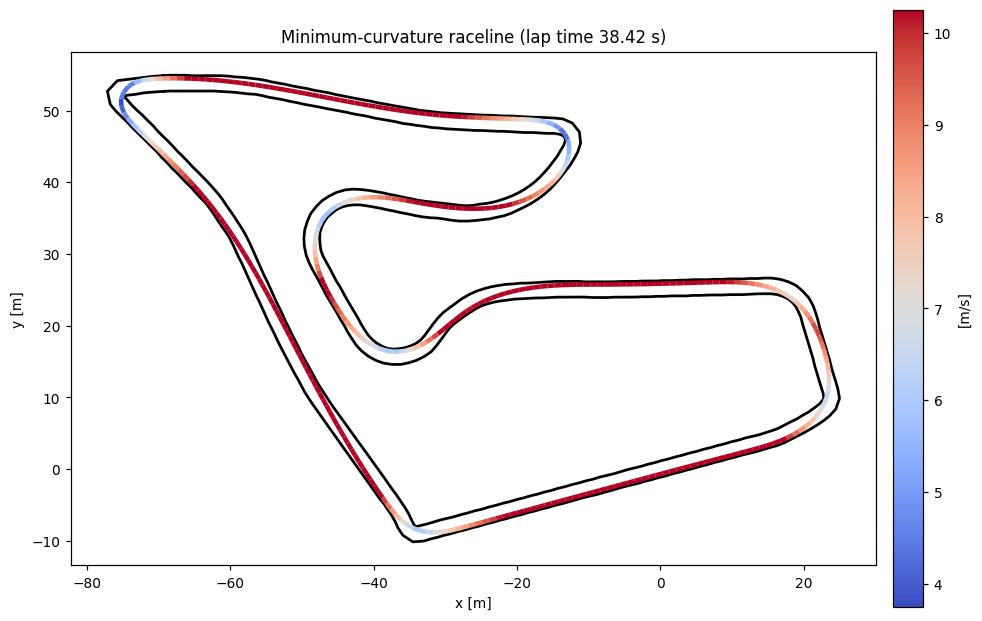

In [12]:
fig, ax = plt.subplots(figsize=(9, 6.5))
plot_loop(ax, LEFT_EDGE, 'k-', lw=1.8)
plot_loop(ax, RIGHT_EDGE, 'k-', lw=1.8)
loop = np.vstack([RACE, RACE[0]])
line = LineCollection(np.stack([loop[:-1], loop[1:]], axis=1), cmap='coolwarm',
                      norm=plt.Normalize(VP['v'].min(), VP['v'].max()))
line.set_array(VP['v'])
line.set_linewidth(3.0)
ax.add_collection(line)
plt.colorbar(line, ax=ax, fraction=0.035, pad=0.02).set_label('[m/s]')
ax.set_aspect('equal')
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_title(f'Minimum-curvature raceline (lap time {VP["lap_time"]:.2f} s)')
ax.autoscale_view()
plt.tight_layout()
plt.show()

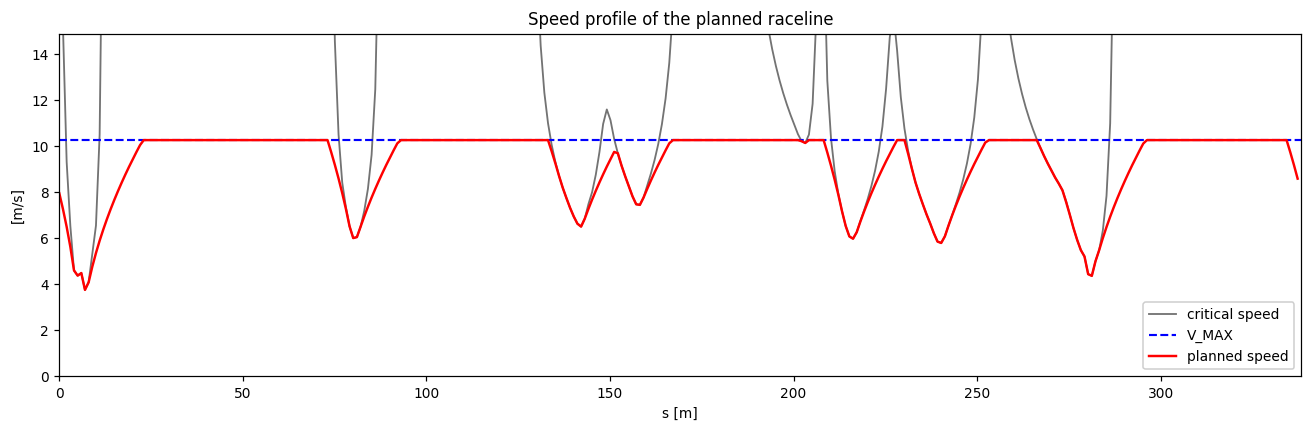

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(VP['s'], VP['v_crit_raw'], color='0.45', lw=1.2, label='critical speed')
ax.axhline(V_MAX, ls='--', color='blue', lw=1.4, label='V_MAX')
ax.plot(VP['s'], VP['v'], color='red', lw=1.6, label='planned speed')
ax.set_xlabel('s [m]')
ax.set_ylabel('[m/s]')
ax.set_xlim(0, VP['length'])
ax.set_ylim(0, V_MAX * 1.45)
ax.legend(loc='lower right', framealpha=0.95)
ax.set_title('Speed profile of the planned raceline')
plt.tight_layout()
plt.show()

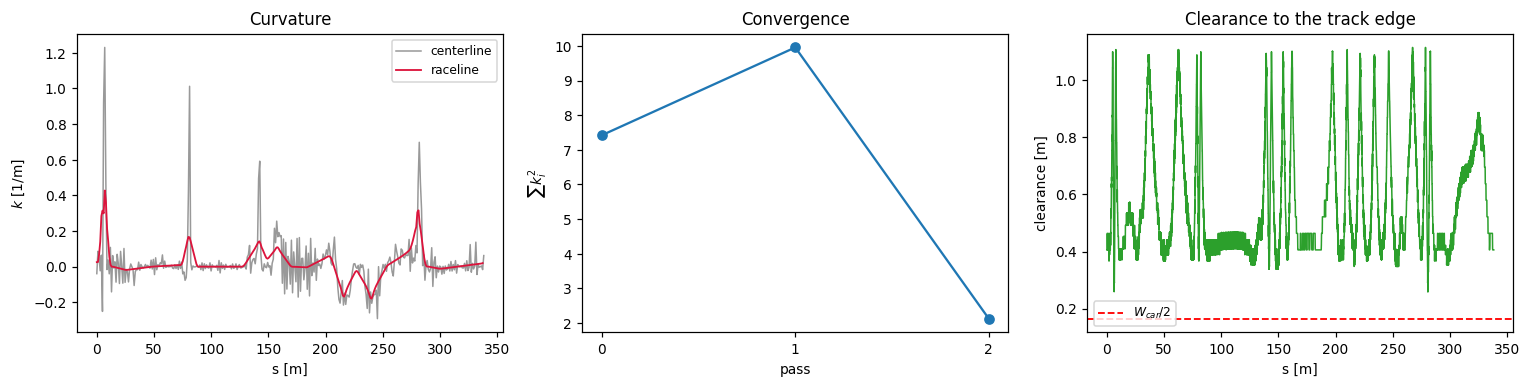

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

axes[0].plot(np.linspace(0, VP['length'], len(K_CENTER)), K_CENTER, color='0.6', lw=1,
             label='centerline')
axes[0].plot(VP['s'], K_RACE, color='crimson', lw=1.2, label='raceline')
axes[0].set_xlabel('s [m]')
axes[0].set_ylabel('$k$ [1/m]')
axes[0].legend(fontsize=8)
axes[0].set_title('Curvature')

passes = range(len(HISTORY))
axes[1].plot(passes, [h['sum_k2'] for h in HISTORY], 'o-', color='tab:blue')
axes[1].set_xlabel('pass')
axes[1].set_ylabel(r'$\sum k_i^2$')
axes[1].set_xticks(passes)
axes[1].set_title('Convergence')

axes[2].plot(np.linspace(0, VP['length'], len(CHECK['clearance'])), CHECK['clearance'],
             color='tab:green', lw=1)
axes[2].axhline(W_CAR / 2, ls='--', color='red', lw=1.2, label='$W_{car}/2$')
axes[2].set_xlabel('s [m]')
axes[2].set_ylabel('clearance [m]')
axes[2].legend(fontsize=8)
axes[2].set_title('Clearance to the track edge')

plt.tight_layout()
plt.show()

## 10. The two tuning parameters, measured

The interpolation distance is the thesis's **only tunable parameter**, and chapter 7 leaves
its trade-off as future work: too large and the raceline leaves the track, too small and
the execution time grows.

The first sweep measures both sides of that trade-off on this map, the second does the same
for `ALPHA_MARGIN`, so that neither value is a guess.

In [15]:
def plan(d_interp, margin):
    """One complete planning run, from the centerline pixels to a validated lap time."""
    t0 = time.perf_counter()
    pts, normals, ds, _ = fit_and_resample(CENTER_XY, d_interp)
    w_left, w_right = track_widths(pts, normals, MAP)
    line, history = minimum_curvature(pts, normals, ds, w_left, w_right, MAP,
                                      d_interp=d_interp, margin=margin, verbose=False)
    elapsed = time.perf_counter() - t0
    return dict(n=len(pts), time=elapsed, **history[-1], **validate(line, MAP, W_CAR),
                lap_time=plan_velocity(line)['lap_time'])


def sweep(name, values, plan_one):
    """plan_one(value) for every value; each row is printed as its run finishes."""
    print(f'{name:>10} {"N":>5} {"time [s]":>9} {"sum k^2":>9} {"length [m]":>11} '
          f'{"clearance":>10} {"off track":>10} {"lap [s]":>8}')
    runs = []
    for value in values:
        r = plan_one(value)
        print(f'{value:10.2f} {r["n"]:5d} {r["time"]:9.2f} {r["sum_k2"]:9.4f} '
              f'{r["length"]:11.2f} {r["min_clearance"]:10.3f} {r["n_outside"]:10d} '
              f'{r["lap_time"]:8.2f}{"" if r["ok"] else "  <-- not drivable"}')
        runs.append(r)
    return runs


D_VALUES = [0.5, 1.0, 1.5, 2.0, 3.0]
D_RUNS = sweep('d [m]', D_VALUES, lambda d: plan(d, ALPHA_MARGIN))
print()
MARGIN_RUNS = sweep('margin [m]', [0.10, 0.15, 0.20, 0.25], lambda margin: plan(D_INTERP, margin))

     d [m]     N  time [s]   sum k^2  length [m]  clearance  off track  lap [s]


      0.50   686      6.61    4.2818      338.54      0.312          0    38.52


      1.00   343      1.46    2.1262      338.32      0.259          0    38.42


      1.50   229      0.81    1.4100      337.73      0.116          0    38.23  <-- not drivable


      2.00   171      1.08    1.0588      337.11      0.000          3    38.10  <-- not drivable


      3.00   114      2.11    0.7104      335.06      0.000         48    37.67  <-- not drivable

margin [m]     N  time [s]   sum k^2  length [m]  clearance  off track  lap [s]


      0.10   343      2.34    2.0186      337.92      0.082          0    38.18  <-- not drivable


      0.15   343      2.96    2.0985      338.14      0.183          0    38.44


      0.20   343      1.52    2.1262      338.32      0.259          0    38.42


      0.25   343      1.53    2.2022      338.61      0.312          0    38.65


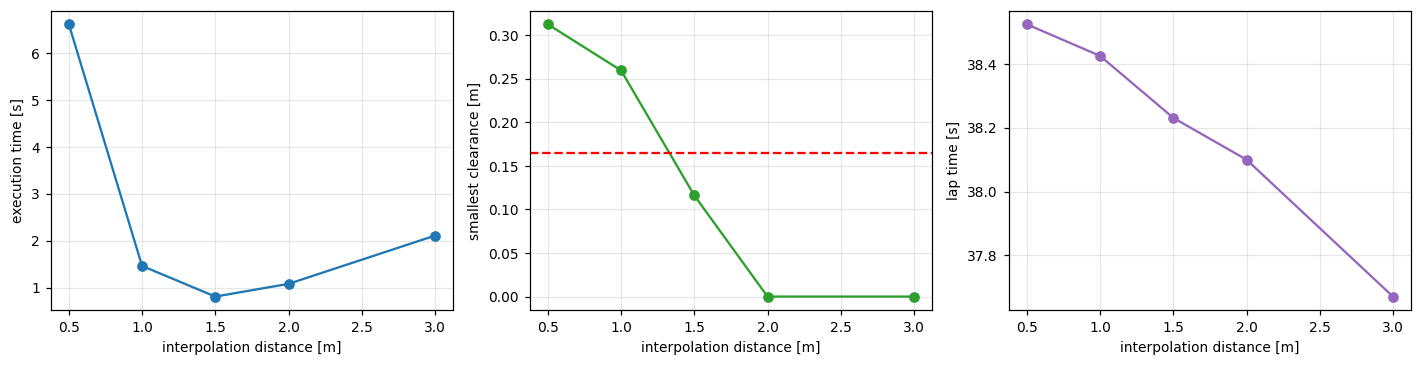

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(D_VALUES, [r['time'] for r in D_RUNS], 'o-')
axes[0].set_ylabel('execution time [s]')
axes[1].plot(D_VALUES, [r['min_clearance'] for r in D_RUNS], 'o-', color='tab:green')
axes[1].axhline(W_CAR / 2, ls='--', color='red')
axes[1].set_ylabel('smallest clearance [m]')
axes[2].plot(D_VALUES, [r['lap_time'] for r in D_RUNS], 'o-', color='tab:purple')
axes[2].set_ylabel('lap time [s]')
for ax in axes:
    ax.set_xlabel('interpolation distance [m]')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Export

`racingline.csv` goes next to the map it was planned on, where `map:=<track>` finds it.
`pure_pursuit_node` reads `x_m`, `y_m` and `v_mps`; the other columns are what an MPC
reference wants: heading, curvature and the critical speed (the thesis's $x_{ref}$,
section 4.4). A line that failed step 7 is not written.

In [17]:
if not CHECK['ok']:
    raise RuntimeError('the raceline failed validation (step 7): nothing exported')

psi = np.unwrap(np.arctan2(np.roll(RACE[:, 1], -1) - RACE[:, 1],
                           np.roll(RACE[:, 0], -1) - RACE[:, 0]))
columns = [VP['s'], RACE[:, 0], RACE[:, 1], psi, VP['k'], VP['v'], VP['v_crit']]
np.savetxt(TRACK_DIR / 'racingline.csv', np.column_stack(columns), delimiter=',', fmt='%.6f',
           header='s_m,x_m,y_m,psi_rad,kappa_radpm,v_mps,v_crit_mps', comments='')

print(f'Wrote {TRACK_DIR / "racingline.csv"} ({len(RACE)} points)')
print(f'  Centerline length  : {L0:.2f} m')
print(f'  Raceline length    : {HISTORY[-1]["length"]:.2f} m')
print(f'  sum k^2            : {HISTORY[0]["sum_k2"]:.4f} -> {HISTORY[-1]["sum_k2"]:.4f}')
print(f'  Predicted lap time : {VP["lap_time"]:.2f} s')
print(f'  Clearance          : {CHECK["min_clearance"]:.3f} m (needs {W_CAR / 2:.3f} m)')

Wrote ../src/rc_maps/tracks/spielberg/racingline.csv (338 points)
  Centerline length  : 342.81 m
  Raceline length    : 338.32 m
  sum k^2            : 7.4224 -> 2.1262
  Predicted lap time : 38.42 s
  Clearance          : 0.259 m (needs 0.165 m)


## Running it on a real SLAM map

* **The map must be closed.** The watershed needs two separate blocked regions, the outside
  and the infield. A track that is open anywhere leaves one region, and step 2 raises.
  Close the gap first, for example with a morphological closing.
* **Filter noise first.** The thesis assumes an already filtered binary map. Stray free
  pixels outside the track create false markers; `ndimage.binary_opening` on `free` before
  step 2 usually fixes it.
* **`prune_spurs` does not rescue everything.** If the ridge has a real shortcut (a loop
  inside the loop), the ordering walk fails with a clear message instead of producing
  nonsense.
* **Always read step 7** before the raceline goes to a controller.
* **Not for the first lap.** The method needs a known, closed map; the lap that builds the
  map is driven reactively (`follow_node`).

For scale: on its Silverstone map the thesis reports 5.27 s of planning, a 179.53 m line
and a 32.50 s predicted lap for this planner (table 6.1).